# Week 3b — Fold-Safe MOFA-Factor Late Integration, SHAP, and Factor Abundance



## 1. Imports, data loading, and setup



In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    balanced_accuracy_score, confusion_matrix
)
from xgboost import XGBClassifier
from mofapy2.run.entry_point import entry_point

RANDOM_STATE = 42
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
MOFA_TMP_DIR = Path("/tmp/mofa_fold_models")
MOFA_TMP_DIR.mkdir(exist_ok=True, parents=True)

# Locate the input files automatically. Put metadata.tsv, genera.tsv and mtb.tsv
# either in ./data, the notebook directory, or /mnt/data/data.
_candidate_dirs = [Path("data"), Path("."), Path("/mnt/data/data"), Path("/mnt/data")]
DATA_DIR = next(
    (p for p in _candidate_dirs if all((p / f).exists() for f in
     ["metadata.tsv", "genera.tsv", "mtb.tsv"])),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find metadata.tsv, genera.tsv and mtb.tsv. "
        "Create a data folder beside this notebook and place all three files inside it, "
        "or set DATA_DIR manually before running this cell."
    )
print(f"Using data directory: {DATA_DIR.resolve()}")


class MicrobiomeFilter(BaseEstimator, TransformerMixin):
    def __init__(self, min_prevalence=0.10, min_mean_abundance=1e-5):
        self.min_prevalence = min_prevalence
        self.min_mean_abundance = min_mean_abundance

    def fit(self, X, y=None):
        X = self._frame(X)
        prevalence = (X.fillna(0) > 0).mean(axis=0)
        mean_abundance = X.fillna(0).mean(axis=0)
        keep = ((prevalence >= self.min_prevalence) &
                (mean_abundance >= self.min_mean_abundance))
        self.feature_names_in_ = X.columns.to_numpy()
        self.selected_features_ = X.columns[keep].tolist()
        if not self.selected_features_:
            raise ValueError("MicrobiomeFilter removed every feature.")
        return self

    def transform(self, X):
        X = self._frame(X)
        return X.reindex(columns=self.selected_features_, fill_value=0.0)

    @staticmethod
    def _frame(X):
        return X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)


class DetectionFilter(BaseEstimator, TransformerMixin):
    def __init__(self, min_detection=0.50):
        self.min_detection = min_detection

    def fit(self, X, y=None):
        X = self._frame(X)
        detection = X.notna().mean(axis=0)
        self.selected_features_ = X.columns[detection >= self.min_detection].tolist()
        if not self.selected_features_:
            raise ValueError("DetectionFilter removed every feature.")
        return self

    def transform(self, X):
        X = self._frame(X)
        return X.reindex(columns=self.selected_features_)

    @staticmethod
    def _frame(X):
        return X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)


def make_xgb(seed=RANDOM_STATE):
    return XGBClassifier(
        n_estimators=250,
        max_depth=2,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.80,
        colsample_bytree=0.80,
        reg_alpha=0.5,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=seed,
        n_jobs=2,
    )


def to_long(df, view_name):
    index_name = df.index.name or "sample"
    tmp = df.copy()
    tmp.index.name = index_name
    long_df = (
        tmp.reset_index()
        .melt(id_vars=index_name, var_name="feature", value_name="value")
        .rename(columns={index_name: "sample"})
    )
    long_df["sample"] = long_df["sample"].astype(str)
    long_df["view"] = view_name
    long_df["group"] = "group1"
    return long_df[["sample", "group", "feature", "view", "value"]]


def top_loadings(weights, factor, feature_label, n=20):
    out = weights.loc[factor].rename("Weight").to_frame()
    out["AbsWeight"] = out["Weight"].abs()
    out = out.sort_values("AbsWeight", ascending=False).head(n).reset_index()
    return out.rename(columns={"index": feature_label})


# Load and align the paired cohort.
metadata = pd.read_csv(DATA_DIR / "metadata.tsv", sep="\t")
genera = pd.read_csv(DATA_DIR / "genera.tsv", sep="\t", index_col=0)
mtb = pd.read_csv(DATA_DIR / "mtb.tsv", sep="\t", index_col=0)

required_metadata_columns = {"Sample", "Study.Group"}
missing_metadata_columns = required_metadata_columns.difference(metadata.columns)
if missing_metadata_columns:
    raise ValueError(
        f"metadata.tsv is missing required columns: {sorted(missing_metadata_columns)}"
    )

metadata["Sample"] = metadata["Sample"].astype(str)
genera.index = genera.index.astype(str)
mtb.index = mtb.index.astype(str)

keep_groups = ["Healthy", "Stage_III_IV"]
metadata_p = (
    metadata.loc[metadata["Study.Group"].isin(keep_groups)]
    .copy()
    .set_index("Sample")
)

common_samples = (
    metadata_p.index
    .intersection(genera.index)
    .intersection(mtb.index)
)
if len(common_samples) == 0:
    raise ValueError(
        "No shared sample IDs were found across metadata, genera and metabolomics."
    )

metadata_p = metadata_p.loc[common_samples].copy()
genera_p = genera.reindex(common_samples).copy()
mtb_p = mtb.reindex(common_samples).copy()
metadata_p["Binary.Group"] = (
    metadata_p["Study.Group"] == "Stage_III_IV"
).astype(int)
y = metadata_p["Binary.Group"].copy()

# MOFA serialises sample names as strings. Normalise and retain one canonical order.
def _string_index(obj, name):
    obj = obj.copy()
    obj.index = obj.index.map(str)
    if not obj.index.is_unique:
        duplicates = obj.index[obj.index.duplicated()].unique().tolist()[:5]
        raise ValueError(
            f"{name} contains duplicate sample IDs after string conversion: {duplicates}"
        )
    return obj

genera_p = _string_index(genera_p, "genera_p")
mtb_p = _string_index(mtb_p, "mtb_p")
metadata_p = _string_index(metadata_p, "metadata_p")
y = _string_index(y, "y")

canonical_ids = y.index
genera_p = genera_p.loc[canonical_ids]
mtb_p = mtb_p.loc[canonical_ids]
metadata_p = metadata_p.loc[canonical_ids]

if y.isna().any():
    raise ValueError("y contains missing labels.")
if y.nunique() != 2:
    raise ValueError(
        f"Binary classification expected, found labels: {sorted(y.unique().tolist())}"
    )

print("Metadata:", metadata_p.shape)
print("Genera:", genera_p.shape)
print("Metabolomics:", mtb_p.shape)
print("\nClass counts:")
print(metadata_p["Study.Group"].value_counts())


Using data directory: /data/scratch/sohaj01/crc_project/data
Metadata: (181, 15)
Genera: (181, 11942)
Metabolomics: (181, 450)

Class counts:
Study.Group
Healthy         127
Stage_III_IV     54
Name: count, dtype: int64


## 2. Fold-safe, per-view preprocessing


In [2]:
def _validate_numeric_frame(X, name):
    if not isinstance(X, pd.DataFrame):
        raise TypeError(f"{name} must be a pandas DataFrame.")
    if X.shape[0] == 0:
        raise ValueError(f"{name} has no samples.")
    if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
        bad = X.columns[~X.dtypes.apply(pd.api.types.is_numeric_dtype)].tolist()[:5]
        raise TypeError(f"{name} contains non-numeric features: {bad}")


def fit_transform_genera_view(X_train_raw, X_test_raw):
    _validate_numeric_frame(X_train_raw, "genera training data")
    _validate_numeric_frame(X_test_raw, "genera test data")

    filt = MicrobiomeFilter(min_prevalence=0.10, min_mean_abundance=1e-5).fit(X_train_raw)
    Xtr = filt.transform(X_train_raw)
    Xte = filt.transform(X_test_raw)

    # Defensive alignment in case a custom transformer returns columns differently.
    Xte = Xte.reindex(columns=Xtr.columns, fill_value=0.0)
    if Xtr.shape[1] == 0:
        raise ValueError("MicrobiomeFilter removed every genus in this training fold.")

    Xtr = np.log1p(Xtr * 1e6)
    Xte = np.log1p(Xte * 1e6)

    scaler = StandardScaler().fit(Xtr)
    Xtr_s = pd.DataFrame(scaler.transform(Xtr), index=Xtr.index, columns=Xtr.columns)
    Xte_s = pd.DataFrame(scaler.transform(Xte), index=Xte.index, columns=Xte.columns)
    return Xtr_s, Xte_s


def fit_transform_mtb_view(X_train_raw, X_test_raw):
    _validate_numeric_frame(X_train_raw, "metabolomics training data")
    _validate_numeric_frame(X_test_raw, "metabolomics test data")

    filt = DetectionFilter(min_detection=0.50).fit(X_train_raw)
    Xtr = filt.transform(X_train_raw)
    Xte = filt.transform(X_test_raw)

    Xte = Xte.reindex(columns=Xtr.columns, fill_value=np.nan)
    if Xtr.shape[1] == 0:
        raise ValueError("DetectionFilter removed every metabolite in this training fold.")

    imputer = SimpleImputer(strategy="median", keep_empty_features=True).fit(Xtr)
    Xtr = pd.DataFrame(imputer.transform(Xtr), index=Xtr.index, columns=Xtr.columns)
    Xte = pd.DataFrame(imputer.transform(Xte), index=Xte.index, columns=Xte.columns)

    # log1p is invalid for values below -1.
    if (Xtr.to_numpy() < -1).any() or (Xte.to_numpy() < -1).any():
        raise ValueError("Metabolomics contains values below -1; log1p cannot be applied safely.")

    Xtr = np.log1p(Xtr)
    Xte = np.log1p(Xte)

    scaler = StandardScaler().fit(Xtr)
    Xtr_s = pd.DataFrame(scaler.transform(Xtr), index=Xtr.index, columns=Xtr.columns)
    Xte_s = pd.DataFrame(scaler.transform(Xte), index=Xte.index, columns=Xte.columns)
    return Xtr_s, Xte_s


def fit_transform_full_views(genera_raw, mtb_raw):
    """Fit descriptive full-cohort preprocessing for the post-CV interpretation section."""
    genera_full, _ = fit_transform_genera_view(genera_raw, genera_raw)
    mtb_full, _ = fit_transform_mtb_view(mtb_raw, mtb_raw)
    return genera_full, mtb_full


## 3. Single-view MOFA+ fit (train fold only) and least-squares projection of held-out samples

In [3]:
def fit_single_view_mofa(X_view_df, view_name, n_factors=8, seed=42,
                         iters=500, convergence_mode="fast"):
    """Fit MOFA+ on one view using only the supplied samples."""
    _validate_numeric_frame(X_view_df, f"{view_name} MOFA input")
    X_view_df = X_view_df.copy()
    X_view_df.index = X_view_df.index.map(str)

    if not np.isfinite(X_view_df.to_numpy()).all():
        raise ValueError(f"{view_name} MOFA input contains NaN or infinite values.")

    effective_factors = min(int(n_factors), X_view_df.shape[0] - 1, X_view_df.shape[1])
    if effective_factors < 1:
        raise ValueError(
            f"Insufficient dimensions for MOFA: {X_view_df.shape[0]} samples, "
            f"{X_view_df.shape[1]} features."
        )

    long_df = to_long(X_view_df, view_name)
    ent = entry_point()
    ent.set_data_options(scale_groups=False, scale_views=False)
    ent.set_data_df(long_df)
    ent.set_model_options(
        factors=effective_factors,
        spikeslab_weights=True,
        ard_weights=True
    )
    ent.set_train_options(
        iter=iters,
        convergence_mode=convergence_mode,
        seed=seed,
        verbose=False
    )
    ent.build()
    ent.run()

    tmp_path = MOFA_TMP_DIR / f"{view_name}_{seed}_{np.random.randint(1_000_000_000)}.hdf5"
    try:
        ent.save(str(tmp_path))
        with h5py.File(tmp_path, "r") as f:
            Z = f["expectations"]["Z"]["group1"][()].T
            W = f["expectations"]["W"][view_name][()]
            sample_names = [
                x.decode() if isinstance(x, bytes) else str(x)
                for x in f["samples"]["group1"][()]
            ]
            feature_names = [
                x.decode() if isinstance(x, bytes) else str(x)
                for x in f["features"][view_name][()]
            ]
    finally:
        tmp_path.unlink(missing_ok=True)

    factor_cols = [f"Factor{i+1}" for i in range(Z.shape[1])]
    Z_df = pd.DataFrame(Z, index=sample_names, columns=factor_cols)
    W_df = pd.DataFrame(W, index=factor_cols, columns=feature_names)
    return Z_df, W_df


def project_new_samples(X_new_df, W_df):
    """Project unseen samples using only training-fold MOFA loadings."""
    X_new_df = X_new_df.copy()
    X_new_df.index = X_new_df.index.map(str)
    X_aligned = X_new_df.reindex(columns=W_df.columns, fill_value=0.0)

    X = X_aligned.to_numpy(dtype=float)
    W = W_df.to_numpy(dtype=float)
    if not np.isfinite(X).all() or not np.isfinite(W).all():
        raise ValueError("Projection input or MOFA loadings contain NaN/infinite values.")

    # Solve W.T @ Z.T ≈ X.T, equivalent to X ≈ Z @ W.
    Z_t, *_ = np.linalg.lstsq(W.T, X.T, rcond=None)
    return pd.DataFrame(Z_t.T, index=X_new_df.index, columns=W_df.index)


## 4. Fold-safe repeated late-integration CV using MOFA factors


In [4]:
def repeated_late_integration_mofa_oof(
    genera_raw, mtb_raw, y,
    n_splits=5, n_repeats=3, n_factors=8, random_state=42
):
    genera_raw = _string_index(genera_raw, "genera_raw")
    mtb_raw = _string_index(mtb_raw, "mtb_raw")
    y = _string_index(y, "y")

    if not genera_raw.index.equals(y.index) or not mtb_raw.index.equals(y.index):
        raise ValueError("genera_raw, mtb_raw, and y must have identical sample IDs and order.")
    if y.value_counts().min() < n_splits:
        raise ValueError(
            f"The minority class has only {y.value_counts().min()} samples; "
            f"n_splits={n_splits} is too large."
        )

    cv = RepeatedStratifiedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=random_state
    )

    rows = []
    prediction_sum = np.zeros(len(y), dtype=float)
    prediction_count = np.zeros(len(y), dtype=int)

    for fold_id, (train_idx, test_idx) in enumerate(cv.split(genera_raw, y), start=1):
        g_train_raw, g_test_raw = genera_raw.iloc[train_idx], genera_raw.iloc[test_idx]
        m_train_raw, m_test_raw = mtb_raw.iloc[train_idx], mtb_raw.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        g_train_proc, g_test_proc = fit_transform_genera_view(g_train_raw, g_test_raw)
        m_train_proc, m_test_proc = fit_transform_mtb_view(m_train_raw, m_test_raw)

        fold_seed = random_state + fold_id
        Zg_train, Wg = fit_single_view_mofa(
            g_train_proc, "Genera", n_factors=n_factors, seed=fold_seed
        )
        Zm_train, Wm = fit_single_view_mofa(
            m_train_proc, "Metabolomics", n_factors=n_factors, seed=fold_seed
        )

        Zg_test = project_new_samples(g_test_proc, Wg)
        Zm_test = project_new_samples(m_test_proc, Wm)

        train_ids = y_train.index
        test_ids = y_test.index
        if not train_ids.isin(Zg_train.index).all() or not train_ids.isin(Zm_train.index).all():
            raise RuntimeError(f"MOFA changed or lost training sample IDs in fold {fold_id}.")
        if not test_ids.isin(Zg_test.index).all() or not test_ids.isin(Zm_test.index).all():
            raise RuntimeError(f"Projection changed or lost test sample IDs in fold {fold_id}.")

        g_model = make_xgb(seed=fold_seed)
        m_model = make_xgb(seed=fold_seed)
        g_model.fit(Zg_train.loc[train_ids], y_train)
        m_model.fit(Zm_train.loc[train_ids], y_train)

        p_g = g_model.predict_proba(Zg_test.loc[test_ids])[:, 1]
        p_m = m_model.predict_proba(Zm_test.loc[test_ids])[:, 1]
        p_late = 0.5 * p_g + 0.5 * p_m

        y_test_arr = y_test.to_numpy()
        repeat_id = (fold_id - 1) // n_splits + 1
        split_id = (fold_id - 1) % n_splits + 1

        rows.append({
            "repeat": repeat_id,
            "fold": split_id,
            "n_test": len(test_idx),
            "auc_genera_mofa": roc_auc_score(y_test_arr, p_g),
            "auc_metabolomics_mofa": roc_auc_score(y_test_arr, p_m),
            "auc_late_mofa": roc_auc_score(y_test_arr, p_late)
        })

        prediction_sum[test_idx] += p_late
        prediction_count[test_idx] += 1

        print(
            f"Fold {fold_id}/{n_splits * n_repeats} done "
            f"(repeat {repeat_id}, split {split_id}) — "
            f"AUC late={rows[-1]['auc_late_mofa']:.3f}"
        )

    if np.any(prediction_count == 0):
        missing_positions = np.flatnonzero(prediction_count == 0).tolist()
        raise RuntimeError(f"Some samples received no OOF prediction: {missing_positions[:10]}")

    fold_metrics = pd.DataFrame(rows)
    mean_oof_probability = prediction_sum / prediction_count
    return fold_metrics, mean_oof_probability


# Start small to confirm the pipeline runs end-to-end, then increase n_repeats.
mofa_fold_metrics, mofa_late_oof_probability = repeated_late_integration_mofa_oof(
    genera_p, mtb_p, y,
    n_splits=5, n_repeats=3, n_factors=8, random_state=RANDOM_STATE
)

mofa_summary = mofa_fold_metrics[
    ["auc_genera_mofa", "auc_metabolomics_mofa", "auc_late_mofa"]
].agg(["mean", "std", "min", "max"]).T
mofa_summary



        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         




Loaded group='group1' view='Genera' with N=144 samples and D=712 features...


Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on the weights: True
Likelihoods:
- View 0 (Genera): gaussian




###############################

,mean,std,min,max
auc_genera_mofa,0.716988,0.072397,0.541818,0.846154
auc_metabolomics_mofa,0.632326,0.141810,0.303846,0.865385
auc_late_mofa,0.725902,0.083780,0.574545,0.903846


Aggregated repeated OOF ROC-AUC (MOFA-factor late integration): 0.737
Aggregated repeated OOF PR-AUC:  0.591
Balanced accuracy at 0.5:        0.632
Confusion matrix at 0.5:
[[123   4]
 [ 38  16]]


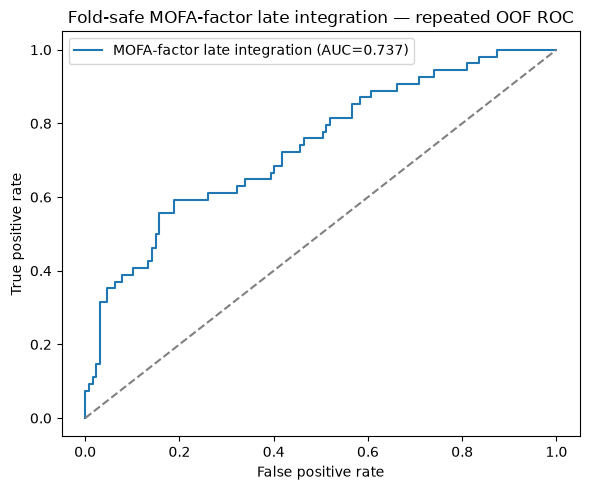

In [9]:
auc_late_mofa = roc_auc_score(y, mofa_late_oof_probability)
ap_late_mofa = average_precision_score(y, mofa_late_oof_probability)
pred_late_mofa = (mofa_late_oof_probability >= 0.5).astype(int)
bal_acc_mofa = balanced_accuracy_score(y, pred_late_mofa)

print(f"Aggregated repeated OOF ROC-AUC (MOFA-factor late integration): {auc_late_mofa:.3f}")
print(f"Aggregated repeated OOF PR-AUC:  {ap_late_mofa:.3f}")
print(f"Balanced accuracy at 0.5:        {bal_acc_mofa:.3f}")
print("Confusion matrix at 0.5:")
print(confusion_matrix(y, pred_late_mofa))

fpr, tpr, _ = roc_curve(y, mofa_late_oof_probability)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"MOFA-factor late integration (AUC={auc_late_mofa:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Fold-safe MOFA-factor late integration — repeated OOF ROC")
plt.legend()
plt.tight_layout()
plt.show()

mofa_fold_metrics.to_csv(OUTPUT_DIR / "mofa_late_integration_repeated_cv_metrics.csv", index=False)
pd.DataFrame({
    "sample": y.index,
    "label": y.values,
    "mean_repeated_oof_probability_mofa": mofa_late_oof_probability
}).to_csv(OUTPUT_DIR / "mofa_late_integration_oof_predictions.csv", index=False)


## 5. Final full-cohort MOFA factors for SHAP interpretation


In [8]:
# Full-cohort preprocessing is fitted here only for descriptive interpretation.
# It is not used to calculate the validated CV performance above.
genera_exp, mtb_exp = fit_transform_full_views(genera_p, mtb_p)

Z_genera_full, W_genera_full = fit_single_view_mofa(
    genera_exp, "Genera", n_factors=8, seed=RANDOM_STATE,
    iters=1000, convergence_mode="fast"
)
Z_mtb_full, W_mtb_full = fit_single_view_mofa(
    mtb_exp, "Metabolomics", n_factors=8, seed=RANDOM_STATE,
    iters=1000, convergence_mode="fast"
)

genera_factor_model = make_xgb(seed=RANDOM_STATE)
mtb_factor_model = make_xgb(seed=RANDOM_STATE)
genera_factor_model.fit(Z_genera_full.loc[y.index], y)
mtb_factor_model.fit(Z_mtb_full.loc[y.index], y)

print("Genera factor matrix:", Z_genera_full.shape)
print("Metabolomics factor matrix:", Z_mtb_full.shape)



        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         




Loaded group='group1' view='Genera' with N=181 samples and D=723 features...


Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on the weights: True
Likelihoods:
- View 0 (Genera): gaussian




###############################

## 6. SHAP analysis per view

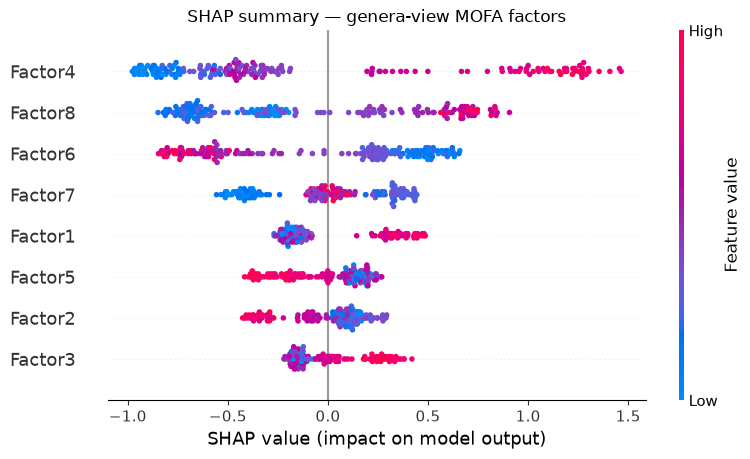

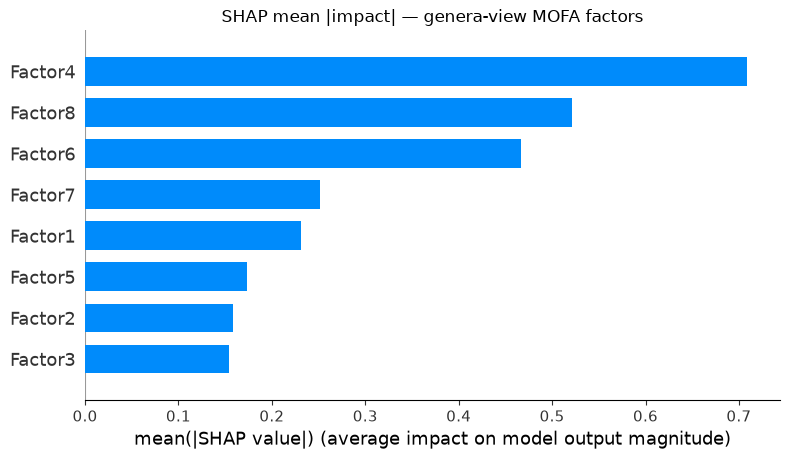

In [10]:
import shap


def _positive_class_shap_values(explainer, X):
    """Return a 2-D SHAP matrix across common SHAP/XGBoost API versions."""
    values = explainer.shap_values(X)
    if isinstance(values, list):
        values = values[-1]
    values = np.asarray(values)
    if values.ndim == 3:
        values = values[:, :, -1]
    if values.ndim != 2:
        raise ValueError(f"Unexpected SHAP array shape: {values.shape}")
    return values


explainer_g = shap.TreeExplainer(genera_factor_model)
shap_values_g = _positive_class_shap_values(explainer_g, Z_genera_full)

shap.summary_plot(shap_values_g, Z_genera_full, show=False)
plt.title("SHAP summary — genera-view MOFA factors")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_genera_mofa_factors.png", dpi=150)
plt.show()

shap.summary_plot(shap_values_g, Z_genera_full, plot_type="bar", show=False)
plt.title("SHAP mean |impact| — genera-view MOFA factors")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_genera_mofa_factors_bar.png", dpi=150)
plt.show()


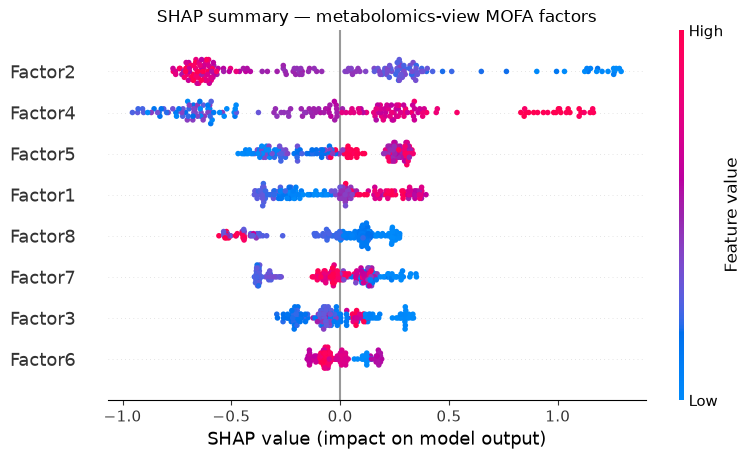

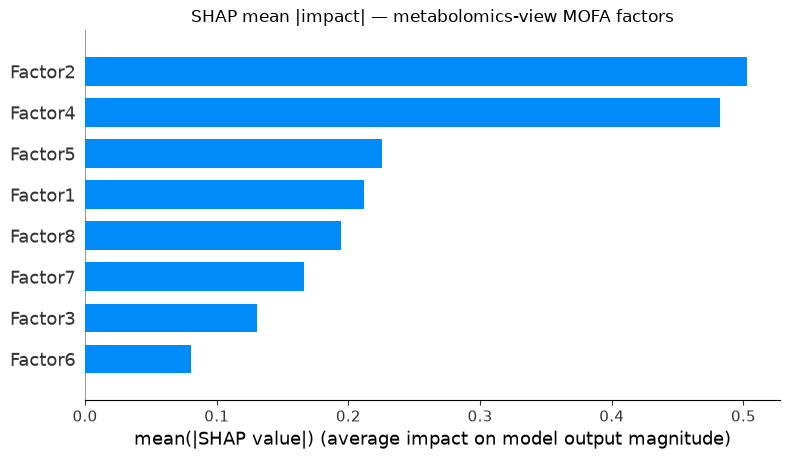

In [11]:
explainer_m = shap.TreeExplainer(mtb_factor_model)
shap_values_m = _positive_class_shap_values(explainer_m, Z_mtb_full)

shap.summary_plot(shap_values_m, Z_mtb_full, show=False)
plt.title("SHAP summary — metabolomics-view MOFA factors")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_mtb_mofa_factors.png", dpi=150)
plt.show()

shap.summary_plot(shap_values_m, Z_mtb_full, plot_type="bar", show=False)
plt.title("SHAP mean |impact| — metabolomics-view MOFA factors")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_mtb_mofa_factors_bar.png", dpi=150)
plt.show()


## 7. Top SHAP-important factor per view → loadings → raw abundance check


In [12]:
def mean_shap_importance(shap_values, factor_names):
    return pd.Series(np.abs(shap_values).mean(axis=0), index=factor_names).sort_values(ascending=False)

genera_factor_importance = mean_shap_importance(shap_values_g, Z_genera_full.columns)
mtb_factor_importance = mean_shap_importance(shap_values_m, Z_mtb_full.columns)

print("Genera-view factor importance (mean |SHAP|):")
print(genera_factor_importance)
print("\nMetabolomics-view factor importance (mean |SHAP|):")
print(mtb_factor_importance)

top_genera_factor = genera_factor_importance.index[0]
top_mtb_factor = mtb_factor_importance.index[0]
print(f"\nTop SHAP-important genera-view factor: {top_genera_factor}")
print(f"Top SHAP-important metabolomics-view factor: {top_mtb_factor}")


Genera-view factor importance (mean |SHAP|):
Factor4    0.708547
Factor8    0.521050
Factor6    0.466537
Factor7    0.251262
Factor1    0.230774
Factor5    0.173021
Factor2    0.158145
Factor3    0.153793
dtype: float32

Metabolomics-view factor importance (mean |SHAP|):
Factor2    0.502609
Factor4    0.482305
Factor5    0.225695
Factor1    0.211878
Factor8    0.194023
Factor7    0.166200
Factor3    0.130615
Factor6    0.080610
dtype: float32

Top SHAP-important genera-view factor: Factor4
Top SHAP-important metabolomics-view factor: Factor2


In [13]:
top_genera_loadings = top_loadings(W_genera_full, top_genera_factor, "Genus", n=20)
top_mtb_loadings = top_loadings(W_mtb_full, top_mtb_factor, "Metabolite", n=20)

display(top_genera_loadings)
display(top_mtb_loadings)

top_genera_loadings.to_csv(OUTPUT_DIR / f"{top_genera_factor}_genera_view_top_loadings.csv", index=False)
top_mtb_loadings.to_csv(OUTPUT_DIR / f"{top_mtb_factor}_mtb_view_top_loadings.csv", index=False)


,Genus,Weight,AbsWeight
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.607289,0.607289
1,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.564089,0.564089
2,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,-0.530742,0.530742
3,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.527030,0.527030
4,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.516994,0.516994
5,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,-0.497214,0.497214
6,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.491316,0.491316
7,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,0.490044,0.490044
8,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,0.485870,0.485870
9,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,-0.481157,0.481157


,Metabolite,Weight,AbsWeight
0,C00099_beta-Ala,0.767180,0.767180
1,"N1,N8-Diacetylspermidine",0.765525,0.765525
2,C00612_N1-Acetylspermidine,0.742356,0.742356
3,C00334_GABA,0.725300,0.725300
4,"C03413_N1,N12-Diacetylspermine",0.692789,0.692789
5,C05771_Isopropanolamine,0.665333,0.665333
6,C00019_SAM+,0.604548,0.604548
7,C02714_N-Acetylputrescine,0.600573,0.600573
8,C00993_Ala-Ala,0.569764,0.569764
9,C01015_Hydroxyproline,0.549984,0.549984


In [14]:
# Raw (unfiltered, pre-log, pre-scale) abundance of the top-loading genera,
# split by disease group — sanity check on biological direction.
if "Study.Group" not in metadata_p.columns:
    raise KeyError("metadata_p must contain a 'Study.Group' column for abundance summaries.")

top_genus_ids = [g for g in top_genera_loadings["Genus"] if g in genera_p.columns]
if not top_genus_ids:
    raise ValueError("None of the top genus loadings match columns in genera_p.")

genus_abundance = genera_p[top_genus_ids].copy()
genus_abundance["Study.Group"] = metadata_p.loc[genus_abundance.index, "Study.Group"]

genus_abundance_summary = genus_abundance.groupby("Study.Group")[top_genus_ids].mean().T
for group in ["Healthy", "Stage_III_IV"]:
    if group not in genus_abundance_summary.columns:
        genus_abundance_summary[group] = np.nan

genus_abundance_summary["difference_stage_minus_healthy"] = (
    genus_abundance_summary["Stage_III_IV"] - genus_abundance_summary["Healthy"]
)
genus_abundance_summary = genus_abundance_summary.sort_values(
    "difference_stage_minus_healthy", ascending=False
)
genus_abundance_summary.to_csv(
    OUTPUT_DIR / f"{top_genera_factor}_top_genera_abundance_by_group.csv"
)
display(genus_abundance_summary)


Study.Group,Healthy,Stage_III_IV,difference_stage_minus_healthy
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae;g__Ruthenibacterium,0.001039,0.002334,0.001295
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Hungatella,0.000484,0.001342,0.000859
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__Flavonifractor,0.002657,0.003337,0.000680
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Acutalibacter,0.000530,0.000762,0.000232
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Merdimonas,0.000177,0.000363,0.000186
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92,0.000425,0.000526,0.000100
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__UMGS1623,0.000010,0.000078,0.000068
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Heritagella,0.000030,0.000060,0.000030
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Butyricicoccaceae;g__Butyricicoccus,0.000209,0.000237,0.000029
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Ventrisoma,0.000123,0.000143,0.000020


In [15]:
# Same check for the top-loading metabolites.
top_mtb_ids = [m for m in top_mtb_loadings["Metabolite"] if m in mtb_p.columns]
if not top_mtb_ids:
    raise ValueError("None of the top metabolite loadings match columns in mtb_p.")

mtb_abundance = mtb_p[top_mtb_ids].copy()
mtb_abundance["Study.Group"] = metadata_p.loc[mtb_abundance.index, "Study.Group"]

mtb_abundance_summary = mtb_abundance.groupby("Study.Group")[top_mtb_ids].mean().T
for group in ["Healthy", "Stage_III_IV"]:
    if group not in mtb_abundance_summary.columns:
        mtb_abundance_summary[group] = np.nan

mtb_abundance_summary["difference_stage_minus_healthy"] = (
    mtb_abundance_summary["Stage_III_IV"] - mtb_abundance_summary["Healthy"]
)
mtb_abundance_summary = mtb_abundance_summary.sort_values(
    "difference_stage_minus_healthy", ascending=False
)
mtb_abundance_summary.to_csv(
    OUTPUT_DIR / f"{top_mtb_factor}_top_metabolites_abundance_by_group.csv"
)
display(mtb_abundance_summary)


Study.Group,Healthy,Stage_III_IV,difference_stage_minus_healthy
C00134_Putrescine,2522.769045,2641.470475,118.701430
C02714_N-Acetylputrescine,521.591366,546.327163,24.735797
C00386_Carnosine,23.189824,25.818311,2.628487
C01234_1-Aminocyclopropane-1-carboxylate,5.910764,2.117849,-3.792915
C01029_N8-Acetylspermidine,28.006488,24.136130,-3.870357
C00019_SAM+,46.171459,41.716174,-4.455285
"C03413_N1,N12-Diacetylspermine",17.026198,10.942312,-6.083886
C00024_Acetyl CoA,41.391895,30.803177,-10.588717
C05771_Isopropanolamine,141.083907,121.348918,-19.734989
"N1,N8-Diacetylspermidine",37.492353,16.957790,-20.534563


In [17]:
import re

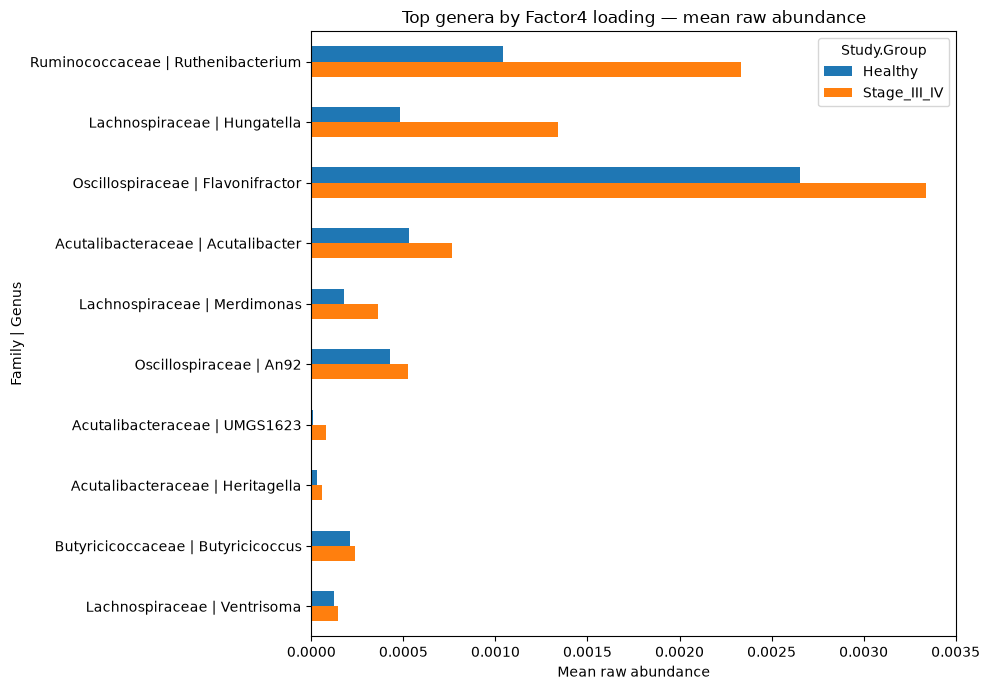

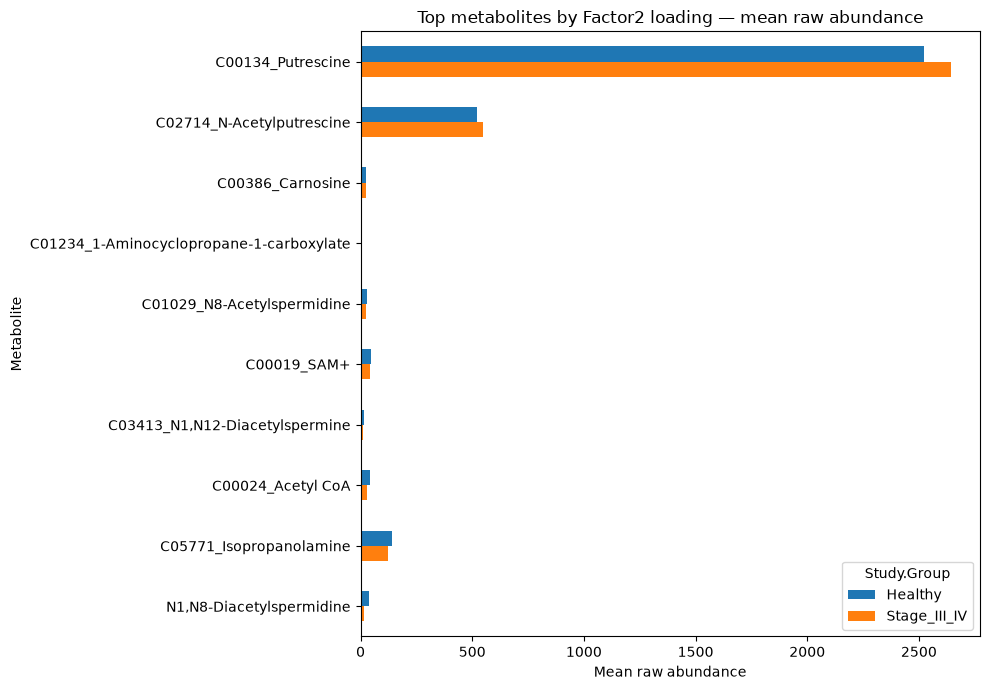

In [18]:
# Visualise top genera and metabolites in separate figures.
required_groups = ["Healthy", "Stage_III_IV"]

# Check that both groups are available.
if genus_abundance_summary[required_groups].isna().all().any():
    missing = [
        group
        for group in required_groups
        if genus_abundance_summary[group].isna().all()
    ]
    raise ValueError(
        f"Missing disease groups in genus abundance summary: {missing}"
    )

if mtb_abundance_summary[required_groups].isna().all().any():
    missing = [
        group
        for group in required_groups
        if mtb_abundance_summary[group].isna().all()
    ]
    raise ValueError(
        f"Missing disease groups in metabolomics abundance summary: {missing}"
    )


def family_genus_label(taxonomy):
    """
    Convert a full taxonomy string into:
        Family | Genus

    Supports labels such as:
        k__Bacteria;p__...;f__Lachnospiraceae;g__Blautia
        d__Bacteria|p__...|f__Lachnospiraceae|g__Blautia
    """
    taxonomy = str(taxonomy)

    # Support semicolon- or pipe-separated taxonomy strings.
    parts = re.split(r"[;|]", taxonomy)

    family = next(
        (
            part.strip()
            for part in parts
            if part.strip().lower().startswith(("f__", "family__"))
        ),
        None,
    )

    genus = next(
        (
            part.strip()
            for part in parts
            if part.strip().lower().startswith(("g__", "genus__"))
        ),
        None,
    )

    # Remove taxonomy prefixes.
    if family:
        family = re.sub(r"^(f__|family__)", "", family, flags=re.IGNORECASE)

    if genus:
        genus = re.sub(r"^(g__|genus__)", "", genus, flags=re.IGNORECASE)

    # Use clearer labels for missing classifications.
    family = family if family else "Unclassified family"
    genus = genus if genus else "Unclassified genus"

    return f"{family} | {genus}"


# ---------------------------------------------------------
# Figure 1: genera
# ---------------------------------------------------------
genus_plot_data = (
    genus_abundance_summary
    .head(10)[required_groups]
    .copy()
)

# Change only the displayed index; the original dataframe is unchanged.
genus_plot_data.index = [
    family_genus_label(label)
    for label in genus_plot_data.index
]

fig, ax = plt.subplots(figsize=(10, 7))

genus_plot_data.plot(
    kind="barh",
    ax=ax,
)

ax.set_title(
    f"Top genera by {top_genera_factor} loading — mean raw abundance"
)
ax.set_xlabel("Mean raw abundance")
ax.set_ylabel("Family | Genus")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "top_genera_abundance_by_group.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------
# Figure 2: metabolites
# ---------------------------------------------------------
metabolite_plot_data = (
    mtb_abundance_summary
    .head(10)[required_groups]
    .copy()
)

fig, ax = plt.subplots(figsize=(10, 7))

metabolite_plot_data.plot(
    kind="barh",
    ax=ax,
)

ax.set_title(
    f"Top metabolites by {top_mtb_factor} loading — mean raw abundance"
)
ax.set_xlabel("Mean raw abundance")
ax.set_ylabel("Metabolite")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "top_metabolites_abundance_by_group.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()